In [4]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("250 project cleaned.csv")
df.head()

,activity_year,state_code,lei,action_taken,derived_race,derived_ethnicity,applicant_age,loan_type,debt_to_income_ratio,derived_msa-md,...,census_tract,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population,denied,age_band,dti_band,tract_minority_band
0,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,35-44,1,30%-<36%,28740,...,36111952100,247.0,585000,52.21,68,3687,0,35-44,30%-<36%,40–<60%
1,2025,NY,7H6GLXDRUGQFU57RNE97,1,Joint,Not Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081026902,100.0,305000,95.74,61,4244,0,35-44,30%-<36%,80–100%
2,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,25-34,1,30%-<36%,35614,...,36119014701,125.0,225000,42.27,122,4977,0,25-34,30%-<36%,40–<60%
3,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Ethnicity Not Available,35-44,1,39,35614,...,36081092800,245.0,605000,9.14,181,3204,0,35-44,36%-49%,0–<20%
4,2025,NY,7H6GLXDRUGQFU57RNE97,2,White,Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081071304,100.0,85000,46.01,125,6386,0,35-44,30%-<36%,40–<60%


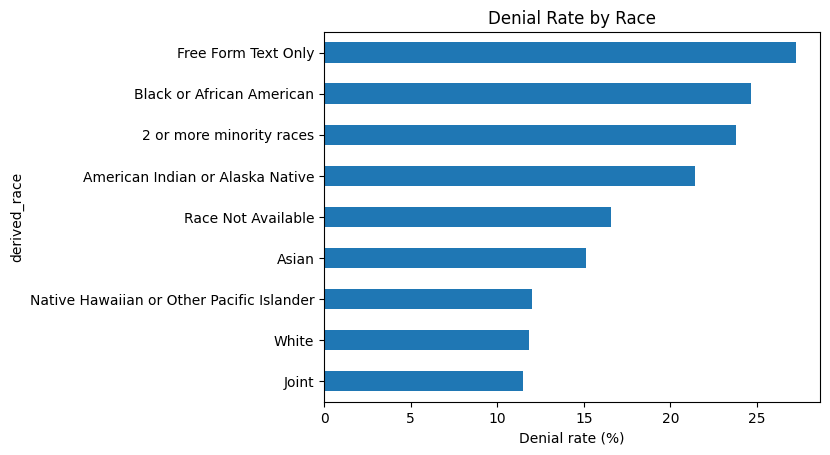

In [5]:
race = df.groupby('derived_race')['denied'].mean() * 100
race.sort_values().plot(kind='barh')
plt.title('Denial Rate by Race')
plt.xlabel('Denial rate (%)')
plt.show()

Black applicants are denied most often among the large groups, at 24.6%. That is about twice the rate for White applicants  11.8%, so a Black applicant in this data was roughly twice as likely to be turned down.


Asian applicants are in between, at 15.1%.
Joint applicants, where one applicant is White and the co-applicant is another race, have the lowest rate at 11.5%. That is about the same as White applicants.


Race Not Available applicants, who did not report their race, are denied 16.6% of the time.


The top bars, like Free Form Text Only at 27.3%, are misleading. Those groups have only 11 to 28 applications each.

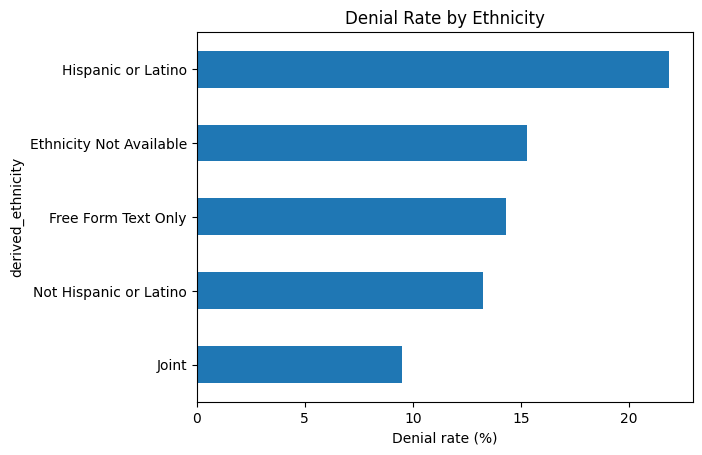

In [7]:
ethnic = df.groupby('derived_ethnicity')['denied'].mean() * 100
ethnic.sort_values().plot(kind='barh')
plt.title('Denial Rate by Ethnicity')
plt.xlabel('Denial rate (%)')
plt.show()

Hispanic or Latino applicants are denied 21.8% of the time, compared with 13.2% for Not Hispanic or Latino applicants. That is about 1.7 times as often.

Joint applicants, with one Hispanic and one non-Hispanic applicant, have the lowest rate at 9.5%.

In [13]:
# Numeric variables
df[['denied', 'income', 'loan_amount', 'tract_minority_population_percent',
    'tract_to_msa_income_percentage', 'tract_population']].describe()


,denied,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population
count,10513.000000,10118.000000,1.051300e+04,10513.000000,10513.000000,10513.000000
mean,0.140398,290.685709,6.694497e+05,42.865117,143.561115,4846.678398
std,0.347416,483.276447,6.924522e+05,25.567725,72.096878,1929.498488
min,0.000000,-719.000000,1.500000e+04,4.170000,0.000000,44.000000
25%,0.000000,106.000000,2.650000e+05,22.520000,92.000000,3497.000000
50%,0.000000,173.000000,4.850000e+05,36.240000,122.000000,4628.000000
75%,0.000000,317.000000,7.950000e+05,60.220000,181.000000,5950.000000
max,1.000000,16328.000000,9.595000e+06,99.780000,292.000000,13385.000000


In [15]:
# Categorical variables: count and denial rate for each group
for col in ['derived_race', 'derived_ethnicity', 'age_band', 'dti_band',
            'loan_type', 'action_taken', 'tract_minority_band']:
    print(df.groupby(col)['denied'].agg(['count', 'mean']))
    print()

                                           count      mean
derived_race                                              
2 or more minority races                      21  0.238095
American Indian or Alaska Native              28  0.214286
Asian                                       2271  0.151035
Black or African American                    808  0.246287
Free Form Text Only                           11  0.272727
Joint                                        452  0.115044
Native Hawaiian or Other Pacific Islander     25  0.120000
Race Not Available                          1056  0.165720
White                                       5841  0.118130

                         count      mean
derived_ethnicity                       
Ethnicity Not Available    831  0.152828
Free Form Text Only         14  0.142857
Hispanic or Latino         934  0.218415
Joint                      326  0.095092
Not Hispanic or Latino    8408  0.132255

          count      mean
age_band                 
25-34     